In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
data_dir = "/content/drive/MyDrive/ratings.csv"

In [3]:
import numpy as np
import pandas as pd
from numba import njit, prange
from scipy.sparse import coo_matrix


dtypes = {"userId":"int32", "movieId":"int32", "rating":"float32"}
df = pd.read_csv(data_dir, usecols=['userId', 'movieId', 'rating'], dtype=dtypes)

# Vectorized mappings

unique_users, user_indices = np.unique(df['userId'].values, return_inverse=True)
unique_items, item_indices = np.unique(df['movieId'].values, return_inverse=True)
ratings = df['rating'].values

n_users = len(unique_users)
n_items = len(unique_items)

print(f"Number of users: {n_users}")
print(f"Number of items: {n_items}")


Number of users: 200948
Number of items: 84432


In [4]:
rng = np.random.default_rng(42)
random_values = rng.random(len(ratings))
train_mask = random_values < 0.8
test_mask = ~train_mask

train_matrix_user = coo_matrix((ratings[train_mask], (user_indices[train_mask], item_indices[train_mask])), shape=(n_users,n_items)).tocsr()
test_matrix_user = coo_matrix((ratings[test_mask], (user_indices[test_mask], item_indices[test_mask])), shape=(n_users,n_items)).tocsr()
train_matrix_item = coo_matrix((ratings[train_mask], (item_indices[train_mask], user_indices[train_mask])), shape=(n_items,n_users)).tocsr()

In [5]:
train_user_indptr = train_matrix_user.indptr
train_user_indices = train_matrix_user.indices
train_user_data = train_matrix_user.data

test_user_indptr = test_matrix_user.indptr
test_user_indices = test_matrix_user.indices
test_user_data = test_matrix_user.data

train_item_indptr = train_matrix_item.indptr
train_item_indices = train_matrix_item.indices
train_item_data = train_matrix_item.data

global_average = np.float32(np.mean(train_user_data))

In [6]:
df = pd.read_csv("/content/drive/MyDrive/ratings.csv", usecols=['userId', 'movieId', 'rating'], dtype="float")

rates = df.to_numpy()
def item_to_index():
  item_to_index = {}
  index = 0
  for row in rates:
    item_id = row[1]
    item_id = int(item_id)
    if item_id not in item_to_index:
      item_to_index[item_id] = index
      index += 1
  return item_to_index

item_to_index = item_to_index()

def index_to_item():
  index_to_item = []
  for item_id, index in item_to_index.items():
    index_to_item.append(item_id)
  return index_to_item

index_to_item = index_to_item()
print("Index 1:", index_to_item[1])

Index 1: 25


In [7]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import TruncatedSVD
from numba import njit, prange

movies = pd.read_csv("/content/drive/MyDrive/movies.csv")

# Raw movie ID -> genres
id_genre = {}

for _, row in movies.iterrows():
    movie_id = int(row["movieId"])
    genres = row["genres"]

    if pd.notna(genres) and genres != "(no genres listed)":
        id_genre[movie_id] = str(genres).split("|")
    else:
        id_genre[movie_id] = []

# k=12 gives us twelve-dimensional user and movie factors
k = 12

# Arrange genres in exactly the same order as the model's item indices
ordered_genre = [
    id_genre.get(int(index_to_item[index]), [])
    for index in range(n_items)
]

# Convert genre lists into binary features
mlb = MultiLabelBinarizer()
V_genre = mlb.fit_transform(ordered_genre).astype(np.float32)

# Reduce the genre features to k dimensions
svd = TruncatedSVD(n_components=k, random_state=42)
V_features = svd.fit_transform(V_genre).astype(np.float32)

# Scale the features to a small initial magnitude
feature_std = np.std(V_features)

if feature_std > 0:
    V_features = V_features / feature_std * 0.01

print("Genre feature matrix:", V_genre.shape)
print("Initial movie vectors:", V_features.shape)
print("Genres:", mlb.classes_)

Genre feature matrix: (84432, 19)
Initial movie vectors: (84432, 12)
Genres: ['Action' 'Adventure' 'Animation' 'Children' 'Comedy' 'Crime'
 'Documentary' 'Drama' 'Fantasy' 'Film-Noir' 'Horror' 'IMAX' 'Musical'
 'Mystery' 'Romance' 'Sci-Fi' 'Thriller' 'War' 'Western']


In [8]:
# G[n] contains the genre indicators for item index n
G = V_genre.astype(np.float32)

assert G.shape[0] == n_items
assert V_features.shape == (n_items, k)

rho_v = 1.0  # Strength of the genre prior

# Initial least-squares mapping from genre features to movie vectors
W = np.linalg.lstsq(G, V_features, rcond=None)[0].astype(np.float32)

print("G shape:", G.shape)
print("W shape:", W.shape)
print("Genre prior strength:", rho_v)

G shape: (84432, 19)
W shape: (19, 12)
Genre prior strength: 1.0


In [9]:
from numba import njit, prange
import numpy as np


@njit(parallel=True, fastmath=True)
def als_algorithm(
    user_indptr, user_indices, user_data,
    item_indptr, item_indices, item_data,
    U, V, user_bias, item_bias, global_average,
    lam, gamma, tau, U_reg, V_reg,
    G, W, rho_v, k
):
    n_users = len(user_indptr) - 1
    n_items = len(item_indptr) - 1
    n_genres = G.shape[1]

    # Update user biases
    for m in prange(n_users):
        start_idx = user_indptr[m]
        end_idx = user_indptr[m + 1]
        count = end_idx - start_idx

        if count == 0:
            continue

        numerator = 0.0

        for i in range(start_idx, end_idx):
            n = user_indices[i]
            r = user_data[i]

            interaction = np.dot(U[m], V[n])

            numerator += lam * (
                r - global_average
                - item_bias[n] - interaction
            )

        user_bias[m] = numerator / (lam * count + gamma)

    # Update user latent factors
    for m in prange(n_users):
        start_idx = user_indptr[m]
        end_idx = user_indptr[m + 1]

        if start_idx == end_idx:
            continue

        A = np.zeros((k, k), dtype=np.float32)
        b = np.zeros(k, dtype=np.float32)

        for i in range(start_idx, end_idx):
            n = user_indices[i]
            r = user_data[i]

            residual = (
                r - global_average
                - user_bias[m] - item_bias[n]
            )

            for a in range(k):
                V_a = V[n, a]
                b[a] += lam * V_a * residual

                for c in range(k):
                    A[a, c] += lam * V_a * V[n, c]

        for a in range(k):
            A[a, a] += U_reg

        U[m] = np.linalg.solve(A, b)

    # Update item biases
    for n in prange(n_items):
        start_idx = item_indptr[n]
        end_idx = item_indptr[n + 1]
        count = end_idx - start_idx

        if count == 0:
            continue

        numerator = 0.0

        for i in range(start_idx, end_idx):
            m = item_indices[i]
            r = item_data[i]

            interaction = np.dot(U[m], V[n])

            numerator += lam * (
                r - global_average
                - user_bias[m] - interaction
            )

        item_bias[n] = numerator / (lam * count + tau)

    # Update item latent factors with the genre prior
    for n in prange(n_items):
        start_idx = item_indptr[n]
        end_idx = item_indptr[n + 1]

        A = np.zeros((k, k), dtype=np.float32)
        b = np.zeros(k, dtype=np.float32)

        # Genre-based prior vector for movie n: G[n] @ W
        prior = np.zeros(k, dtype=np.float32)

        for g in range(n_genres):
            for a in range(k):
                prior[a] += G[n, g] * W[g, a]

        # Rating-based least-squares terms
        for i in range(start_idx, end_idx):
            m = item_indices[i]
            r = item_data[i]

            residual = (
                r - global_average
                - user_bias[m] - item_bias[n]
            )

            for a in range(k):
                U_a = U[m, a]
                b[a] += lam * U_a * residual

                for c in range(k):
                    A[a, c] += lam * U_a * U[m, c]

        # Add ordinary factor regularization and genre prior
        for a in range(k):
            A[a, a] += V_reg + rho_v
            b[a] += rho_v * prior[a]

        V[n] = np.linalg.solve(A, b)

In [10]:
@njit
def calculate_sse(
    user_indptr, user_data, user_indices,
    U, V, user_bias, item_bias, global_average
):
    n_users = len(user_indptr) - 1

    squared_error = 0.0
    count = 0

    for m in range(n_users):
        start_idx = user_indptr[m]
        end_idx = user_indptr[m + 1]

        for i in range(start_idx, end_idx):
            n = user_indices[i]
            r = user_data[i]

            prediction = (
                global_average
                + user_bias[m]
                + item_bias[n]
                + np.dot(U[m], V[n])
            )

            error = r - prediction
            squared_error += error ** 2
            count += 1

    return squared_error, count

In [11]:
lam = 0.1
gamma = 0.5
tau = 0.1

U_reg = 0.1
V_reg = 0.1
rho_v = 1.0
epochs = 20

rng = np.random.default_rng(42)

U = rng.normal(
    0, 0.01, size=(n_users, k)
).astype(np.float32)

V = V_features.copy().astype(np.float32)

user_bias = np.zeros(n_users, dtype=np.float32)
item_bias = np.zeros(n_items, dtype=np.float32)

# Fit the initial genre mapping to the initial movie vectors
W = np.linalg.lstsq(G, V, rcond=None)[0].astype(np.float32)

train_loss, test_loss = [], []
train_rmse, test_rmse = [], []
objective_history = []

for epoch in range(epochs):

    # Update biases and latent factors
    als_algorithm(
        train_user_indptr,
        train_user_indices,
        train_user_data,
        train_item_indptr,
        train_item_indices,
        train_item_data,
        U, V,
        user_bias, item_bias,
        global_average,
        lam, gamma, tau,
        U_reg, V_reg,
        G, W, rho_v, k
    )

    # Refit W to the updated movie vectors
    W = np.linalg.lstsq(G, V, rcond=None)[0].astype(np.float32)

    # Evaluate training data
    train_sse, train_count = calculate_sse(
        train_user_indptr,
        train_user_data,
        train_user_indices,
        U, V, user_bias, item_bias, global_average
    )

    # Evaluate held-out test data
    test_sse, test_count = calculate_sse(
        test_user_indptr,
        test_user_data,
        test_user_indices,
        U, V, user_bias, item_bias, global_average
    )

    if train_count == 0 or test_count == 0:
        raise ValueError("Training and test sets must be non-empty.")

    train_mse = train_sse / train_count
    test_mse = test_sse / test_count

    train_rmse_value = np.sqrt(train_mse)
    test_rmse_value = np.sqrt(test_mse)

    # Calculate all regularization penalties
    genre_prior = G @ W

    genre_penalty = rho_v * np.sum((V - genre_prior) ** 2)

    regularization = (
        gamma * np.sum(user_bias ** 2)
        + tau * np.sum(item_bias ** 2)
        + U_reg * np.sum(U ** 2)
        + V_reg * np.sum(V ** 2)
        + genre_penalty
    )

    objective = lam * train_sse + regularization

    train_loss.append(train_mse)
    test_loss.append(test_mse)
    train_rmse.append(train_rmse_value)
    test_rmse.append(test_rmse_value)
    objective_history.append(objective)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train MSE: {train_mse:.4f} | "
        f"Test MSE: {test_mse:.4f} | "
        f"Train RMSE: {train_rmse_value:.4f} | "
        f"Test RMSE: {test_rmse_value:.4f} | "
        f"Genre penalty: {genre_penalty:.4f} | "
        f"Objective: {objective:.4f}"
    )

Epoch 1/20 | Train MSE: 0.6979 | Test MSE: 0.7552 | Train RMSE: 0.8354 | Test RMSE: 0.8690 | Genre penalty: 8227.4434 | Objective: 1822186.5000
Epoch 2/20 | Train MSE: 0.5504 | Test MSE: 0.6841 | Train RMSE: 0.7419 | Test RMSE: 0.8271 | Genre penalty: 13194.9209 | Objective: 1474724.8750
Epoch 3/20 | Train MSE: 0.5162 | Test MSE: 0.6496 | Train RMSE: 0.7184 | Test RMSE: 0.8059 | Genre penalty: 15596.2480 | Objective: 1389856.6250
Epoch 4/20 | Train MSE: 0.5011 | Test MSE: 0.6339 | Train RMSE: 0.7079 | Test RMSE: 0.7962 | Genre penalty: 17020.2812 | Objective: 1352395.8750
Epoch 5/20 | Train MSE: 0.4932 | Test MSE: 0.6256 | Train RMSE: 0.7023 | Test RMSE: 0.7909 | Genre penalty: 17993.0840 | Objective: 1332272.5000
Epoch 6/20 | Train MSE: 0.4883 | Test MSE: 0.6205 | Train RMSE: 0.6988 | Test RMSE: 0.7877 | Genre penalty: 18712.8359 | Objective: 1319761.7500
Epoch 7/20 | Train MSE: 0.4851 | Test MSE: 0.6172 | Train RMSE: 0.6965 | Test RMSE: 0.7856 | Genre penalty: 19276.3164 | Objective:

In [12]:
def save_svg(filename):
    plt.savefig(filename + ".svg", format="svg", bbox_inches="tight")

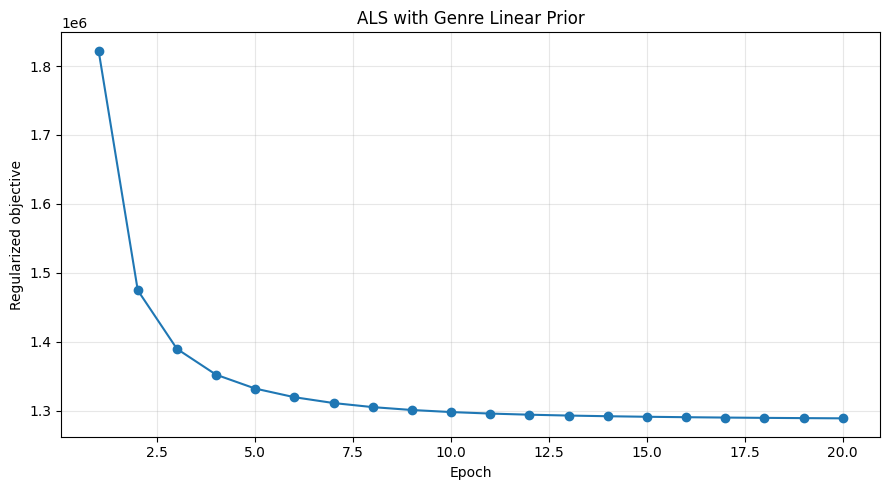

Objective non-increasing: True


In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(objective_history) + 1),
    objective_history,
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Regularized objective")
plt.title("ALS with Genre Linear Prior")
plt.grid(alpha=0.3)
plt.tight_layout()
save_svg("ALS_Genre_LP")
plt.show()

objective_changes = np.diff(objective_history)

print(
    "Objective non-increasing:",
    np.all(objective_changes <= 1e-5)
)